Anggota Kelompok:

1. Orchidea Savira Putri Arief Dhidin (25031554174)

2. Dentar Muhammad Ababilla (25031554277)

# **Exercise 6 Text Similarity**
Try applying the **text similarity** on the text you have **feature engineering from the previous exercise** and analyze the given results.



## **1. Persiapan Environment & Import Library**

In [1]:
!pip install gensim -q

In [2]:
import warnings
warnings.filterwarnings(action='ignore')

import re, string, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from bs4 import BeautifulSoup
from IPython.display import display

import nltk
nltk.download('punkt'); nltk.download('punkt_tab')
nltk.download('stopwords'); nltk.download('wordnet'); nltk.download('omw-1.4')
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import jaccard_score
from scipy.spatial.distance import pdist, squareform, cdist
import gensim.models

pd.set_option('display.max_colwidth', 90)
pd.set_option('display.width', 200)
print("Semua library berhasil dimuat!")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


Semua library berhasil dimuat!


## **2. Load Data Hasil Preprocessing**


In [3]:
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess(text):
    text = str(text).lower()
    text = text.translate(str.maketrans("", "", string.punctuation))
    text = re.sub(r"\d+", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    tokens = [t for t in word_tokenize(text) if t not in stop_words]
    return " ".join(lemmatizer.lemmatize(t) for t in tokens)

def finalize(series):
    s = series.fillna('').astype(str).apply(lambda t: re.sub(r'[^a-z\s]', ' ', t.lower()))
    return s.apply(lambda t: re.sub(r'\s+', ' ', t).strip())

def rebuild_from_scratch():
    quotes = []
    for page in range(1, 6):
        r = requests.get(f"http://quotes.toscrape.com/page/{page}/")
        if r.status_code == 200:
            soup = BeautifulSoup(r.text, "html.parser")
            for box in soup.find_all("div", class_="quote"):
                quotes.append(box.find("span", class_="text").get_text(strip=True))
        time.sleep(0.3)
    d_http = pd.DataFrame({"quote": quotes})
    d_http["quote_final"] = d_http["quote"].apply(preprocess)
    d_http.to_csv("hasil_preprocessing_http.csv", index=False)

    records = []
    for term in ["love", "dream", "night", "sky", "fire"]:
        try:
            res = requests.get("https://itunes.apple.com/search",
                               params={"term": term, "media": "music", "entity": "song", "limit": 3}, timeout=10)
            if res.status_code == 200:
                records.extend(res.json().get("results", []))
        except requests.exceptions.RequestException as e:
            print(term, "error:", e)
        time.sleep(0.3)
    d_music = pd.DataFrame(records)
    if d_music.empty:
        d_music = pd.DataFrame({"trackName": ["Bohemian Rhapsody", "Imagine", "Hotel California", "Billie Jean", "Shape of You"],
                                "artistName": ["Queen", "John Lennon", "Eagles", "Michael Jackson", "Ed Sheeran"]})
    d_music["raw_text"] = d_music["trackName"].astype(str) + " " + d_music["artistName"].astype(str)
    d_music["music_final"] = d_music["raw_text"].apply(preprocess)
    d_music.to_csv("hasil_preprocessing_music_api.csv", index=False)

try:
    df_http = pd.read_csv('hasil_preprocessing_http.csv')
    df_music = pd.read_csv('hasil_preprocessing_music_api.csv')
    print("CSV Exercise 4 ditemukan dan dibaca.")
except FileNotFoundError:
    print("CSV tidak ditemukan -> scraping & preprocessing ulang ...")
    rebuild_from_scratch()
    df_http = pd.read_csv('hasil_preprocessing_http.csv')
    df_music = pd.read_csv('hasil_preprocessing_music_api.csv')

df_http['prepro'] = finalize(df_http['quote_final'])
df_music['prepro'] = finalize(df_music['music_final'])
df_http = df_http[df_http['prepro'] != ''].reset_index(drop=True)
df_music = df_music[df_music['prepro'] != ''].reset_index(drop=True)

df_http['display'] = df_http['quote'] if 'quote' in df_http.columns else df_http['prepro']
df_music['display'] = df_music['raw_text'] if 'raw_text' in df_music.columns else df_music['prepro']

datasets = {'Quotes': df_http, 'Music': df_music}
for name, d in datasets.items():
    print(f"{name}: {len(d)} dokumen | contoh: {d['prepro'].iloc[0]}")

CSV tidak ditemukan -> scraping & preprocessing ulang ...
Quotes: 50 dokumen | contoh: world created process thinking changed without changing thinking
Music: 15 dokumen | contoh: love keyshia cole


## **3. Feature Engineerin**


In [4]:
def doc_vector(tokens, model):
    vecs = [model.wv[w] for w in tokens if w in model.wv]
    return np.mean(vecs, axis=0) if vecs else np.zeros(model.vector_size)

feat = {}
for name, d in datasets.items():
    docs = d['prepro']
    sents = [word_tokenize(t.lower()) for t in docs]
    f = {}
    f['vec_bin']   = CountVectorizer(binary=True).fit(docs)
    f['vec_count'] = CountVectorizer().fit(docs)
    f['vec_tfidf'] = TfidfVectorizer().fit(docs)
    f['Binary BoW'] = f['vec_bin'].transform(docs).toarray()
    f['Count']      = f['vec_count'].transform(docs).toarray()
    f['TF-IDF']     = f['vec_tfidf'].transform(docs).toarray()
    f['w2v'] = gensim.models.Word2Vec(sents, min_count=1, vector_size=100, window=5, sg=0, epochs=100, seed=42, workers=1)
    f['ft']  = gensim.models.FastText(sents, min_count=1, vector_size=100, window=5, min_n=3, max_n=6, sg=1, epochs=100, seed=42, workers=1)
    f['Word2Vec'] = np.array([doc_vector(s, f['w2v']) for s in sents])
    f['FastText'] = np.array([doc_vector(s, f['ft']) for s in sents])
    feat[name] = f
    print(f"{name}: " + " | ".join(f"{k} {feat[name][k].shape}" for k in ['Binary BoW','Count','TF-IDF','Word2Vec','FastText']))

Quotes: Binary BoW (50, 321) | Count (50, 321) | TF-IDF (50, 321) | Word2Vec (50, 100) | FastText (50, 100)
Music: Binary BoW (15, 37) | Count (15, 37) | TF-IDF (15, 37) | Word2Vec (15, 100) | FastText (15, 100)


## **4. Cosine Similarity**


### **A. Matriks Cosine Similarity (Count vs TF-IDF)**

In [5]:
sim = {name: {} for name in datasets}
for name in datasets:
    for k in ['Count', 'TF-IDF', 'Word2Vec', 'FastText']:
        sim[name][f'Cosine-{k}'] = cosine_similarity(feat[name][k])

for name in datasets:
    n = len(datasets[name])
    k = min(n, 6)
    print(f"=== {name}: Cosine Similarity Count (6 dokumen pertama) ===")
    print(np.round(sim[name]['Cosine-Count'][:k, :k], 3))
    print(f"=== {name}: Cosine Similarity TF-IDF (6 dokumen pertama) ===")
    print(np.round(sim[name]['Cosine-TF-IDF'][:k, :k], 3))
    print()

=== Quotes: Cosine Similarity Count (6 dokumen pertama) ===
[[1. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0. 0.]
 [0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 0. 1.]]
=== Quotes: Cosine Similarity TF-IDF (6 dokumen pertama) ===
[[1. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0. 0.]
 [0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 0. 1.]]

=== Music: Cosine Similarity Count (6 dokumen pertama) ===
[[1.    0.333 0.258 0.    0.    0.   ]
 [0.333 1.    0.258 0.    0.    0.   ]
 [0.258 0.258 1.    0.    0.    0.   ]
 [0.    0.    0.    1.    0.408 0.408]
 [0.    0.    0.    0.408 1.    0.5  ]
 [0.    0.    0.    0.408 0.5   1.   ]]
=== Music: Cosine Similarity TF-IDF (6 dokumen pertama) ===
[[1.    0.231 0.174 0.    0.    0.   ]
 [0.231 1.    0.174 0.    0.    0.   ]
 [0.174 0.174 1.    0.    0.    0.   ]
 [0.    0.    0.    1.    0.294 0.294]
 [0.    0.    0.    0.294 1.    0.375]
 [0.    0.    0.    0.294 0.375 1.   ]]



### **B. Cosine Distance dengan `pdist`**


In [6]:
for name in datasets:
    Xb = feat[name]['Binary BoW']
    dist_vec = 1 - pdist(Xb, metric='cosine')
    from_sk = cosine_similarity(Xb)[np.triu_indices(len(Xb), k=1)]
    print(f"{name}: 1 - pdist(cosine) sama dengan cosine_similarity? ->", np.allclose(dist_vec, from_sk))
    print("  contoh 5 pasangan pertama:", np.round(dist_vec[:5], 4))

Quotes: 1 - pdist(cosine) sama dengan cosine_similarity? -> True
  contoh 5 pasangan pertama: [0. 0. 0. 0. 0.]
Music: 1 - pdist(cosine) sama dengan cosine_similarity? -> True
  contoh 5 pasangan pertama: [0.3333 0.2582 0.     0.     0.    ]


### **C. Heatmap Cosine Similarity**

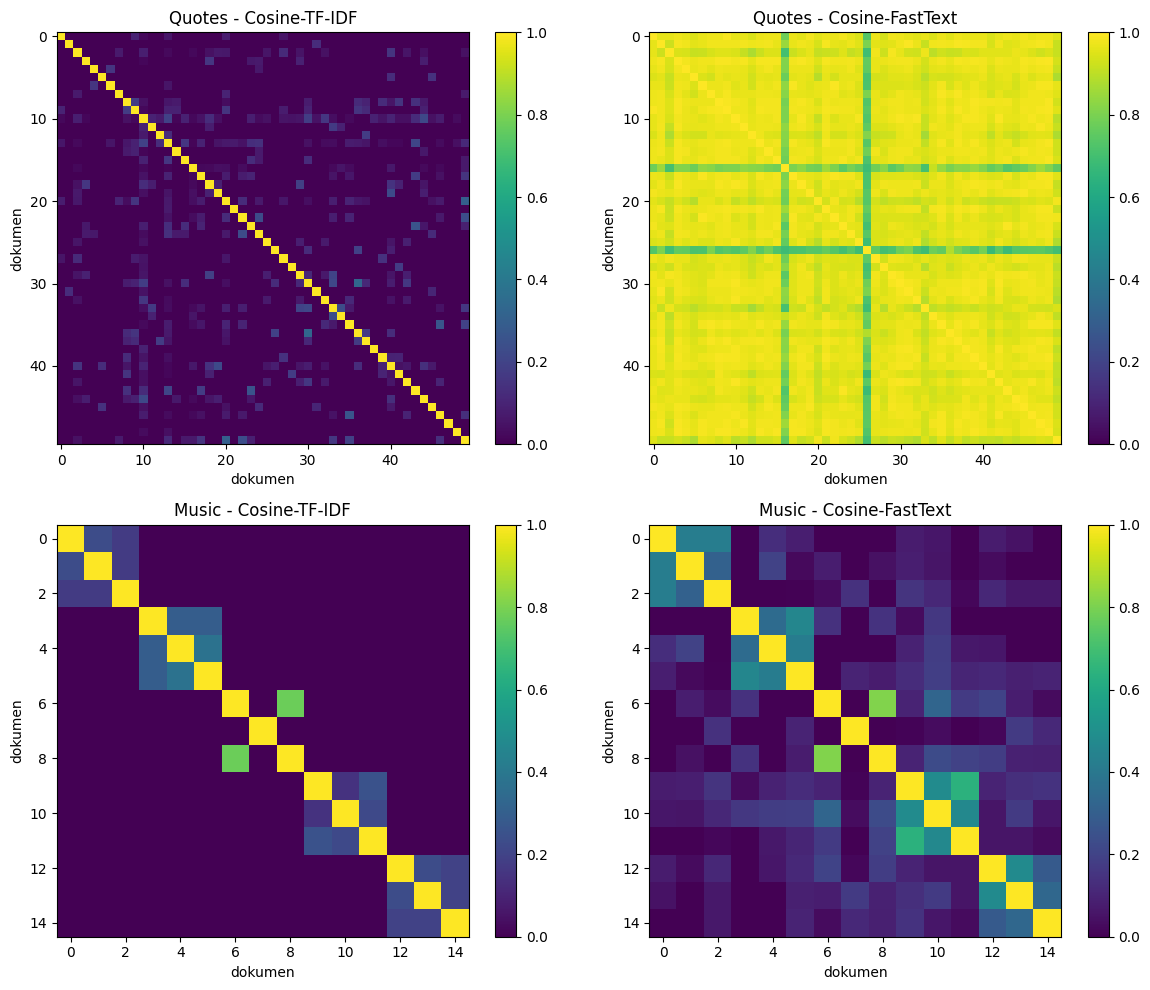

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for r, name in enumerate(datasets):
    for c, k in enumerate(['Cosine-TF-IDF', 'Cosine-FastText']):
        ax = axes[r, c]
        im = ax.imshow(sim[name][k], cmap='viridis', vmin=0, vmax=1)
        ax.set_title(f'{name} - {k}')
        ax.set_xlabel('dokumen'); ax.set_ylabel('dokumen')
        plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()

## **5. Jaccard Similarity**

In [8]:
for name in datasets:
    Xb = feat[name]['Binary BoW'].astype(bool)
    jac_dist = pdist(Xb, metric='jaccard')
    sim[name]['Jaccard-Binary'] = 1 - squareform(jac_dist)
    np.fill_diagonal(sim[name]['Jaccard-Binary'], 1.0)

    print(f"=== {name} ===")
    print("Jaccard distance 5 pasangan pertama :", np.round(jac_dist[:5], 4))
    s12 = jaccard_score(Xb[0], Xb[1])
    print("jaccard_score(doc 0, doc 1)         :", round(s12, 4))
    print("1 - distance(doc 0, doc 1)          :", round(1 - jac_dist[0], 4), "-> sama:", np.isclose(s12, 1 - jac_dist[0]))
    print()

=== Quotes ===
Jaccard distance 5 pasangan pertama : [1. 1. 1. 1. 1.]
jaccard_score(doc 0, doc 1)         : 0.0
1 - distance(doc 0, doc 1)          : 0.0 -> sama: True

=== Music ===
Jaccard distance 5 pasangan pertama : [0.8    0.8571 1.     1.     1.    ]
jaccard_score(doc 0, doc 1)         : 0.2
1 - distance(doc 0, doc 1)          : 0.2 -> sama: True



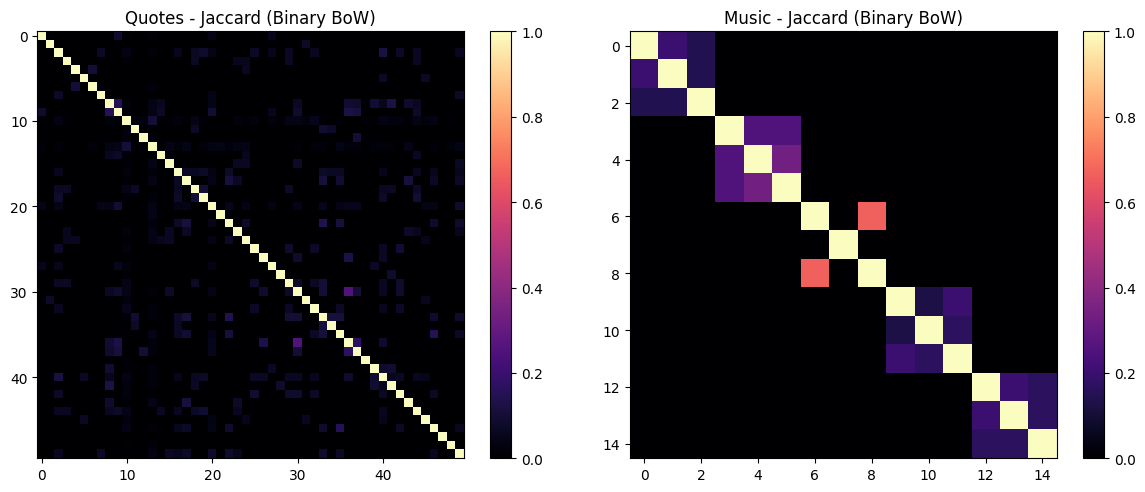

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, name in zip(axes, datasets):
    im = ax.imshow(sim[name]['Jaccard-Binary'], cmap='magma', vmin=0, vmax=1)
    ax.set_title(f'{name} - Jaccard (Binary BoW)')
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()

## **6. Other Distance Functions**

In [16]:
metrics = {'Euclidean': dict(metric='euclidean'), 'Manhattan': dict(metric='cityblock'),
           'Minkowski(p=3)': dict(metric='minkowski', p=3), 'Chebyshev': dict(metric='chebyshev')}

dist_tables = {}
for name in datasets:
    rows = []
    for feat_name in ['TF-IDF', 'FastText']:
        X = feat[name][feat_name]
        for mname, kw in metrics.items():
            D = squareform(pdist(X, **kw))
            sim[name][f'{mname}-{feat_name}'] = 1 / (1 + D)
            off = D[np.triu_indices(len(X), k=1)]
            rows.append({'Fitur': feat_name, 'Jarak': mname, 'rata-rata': off.mean(), 'min': off.min(), 'maks': off.max()})
    dist_tables[name] = pd.DataFrame(rows).round(4)
    print(f"{name}: statistik jarak antar dokumen")
    display(dist_tables[name])

Quotes: statistik jarak antar dokumen


,Fitur,Jarak,rata-rata,min,maks
0,TF-IDF,Euclidean,1.4030,1.1564,1.4142
1,TF-IDF,Manhattan,5.3080,2.9426,11.4911
2,TF-IDF,Minkowski(p=3),0.9390,0.6635,1.0610
3,TF-IDF,Chebyshev,0.5731,0.3338,0.7101
4,FastText,Euclidean,0.4756,0.1615,1.4311
5,FastText,Manhattan,3.7993,1.2634,11.2000
6,FastText,Minkowski(p=3),0.2576,0.0896,0.7784
7,FastText,Chebyshev,0.1337,0.0405,0.4555


Music: statistik jarak antar dokumen


,Fitur,Jarak,rata-rata,min,maks
0,TF-IDF,Euclidean,1.3870,0.6702,1.4142
1,TF-IDF,Manhattan,3.3624,0.9491,4.4524
2,TF-IDF,Minkowski(p=3),1.0442,0.6381,1.1312
3,TF-IDF,Chebyshev,0.6853,0.4662,0.7904
4,FastText,Euclidean,0.0126,0.0068,0.0170
5,FastText,Manhattan,0.1019,0.0563,0.1367
6,FastText,Minkowski(p=3),0.0068,0.0036,0.0091
7,FastText,Chebyshev,0.0033,0.0018,0.0046


## **7. Analisis Pasangan Dokumen Paling Mirip**


In [17]:
def top_pairs(S, docs, k=5):
    n = len(S)
    iu, ju = np.triu_indices(n, k=1)
    keep = np.array([docs[i] != docs[j] for i, j in zip(iu, ju)])
    iu, ju = iu[keep], ju[keep]
    vals = S[iu, ju]
    order = np.argsort(vals)[::-1][:k]
    return pd.DataFrame({'doc A': iu[order], 'doc B': ju[order], 'skor': vals[order].round(4),
                         'teks A': [docs[i] for i in iu[order]], 'teks B': [docs[j] for j in ju[order]]})

main_methods = ['Cosine-Count', 'Cosine-TF-IDF', 'Jaccard-Binary', 'Cosine-Word2Vec', 'Cosine-FastText']
for name, d in datasets.items():
    docs = d['prepro'].tolist()
    dup = sum(1 for i in range(len(docs)) for j in range(i+1, len(docs)) if docs[i] == docs[j])
    print(f"{name} | pasangan dokumen identik (dikeluarkan): {dup}")
    for m in main_methods:
        print(f"{m}: 3 pasangan paling mirip")
        display(top_pairs(sim[name][m], docs, k=3))

Quotes | pasangan dokumen identik (dikeluarkan): 0
Cosine-Count: 3 pasangan paling mirip


,doc A,doc B,skor,teks A,teks B
0,20,49,0.4698,love without knowing love simply without problem pride love way know way loving intima...,love begin end way seem think love battle love war love growing
1,30,36,0.4364,read thing know learn place youll go,read know alone
2,22,49,0.4082,judge people time love,love begin end way seem think love battle love war love growing


Cosine-TF-IDF: 3 pasangan paling mirip


,doc A,doc B,skor,teks A,teks B
0,30,36,0.3314,read thing know learn place youll go,read know alone
1,20,49,0.3045,love without knowing love simply without problem pride love way know way loving intima...,love begin end way seem think love battle love war love growing
2,35,46,0.2619,need love little chocolate doesnt hurt,wise girl kiss doesnt love listens doesnt believe leaf left


Jaccard-Binary: 3 pasangan paling mirip


...

,doc A,doc B,skor,teks A,teks B
0,6,8,0.6667,night pello,night sleep pello
1,4,5,0.3333,dream lisa,dream mario
2,3,5,0.2500,dream salvia palth,dream mario


Cosine-Word2Vec: 3 pasangan paling mirip


,doc A,doc B,skor,teks A,teks B
0,6,8,0.8439,night pello,night sleep pello
1,0,1,0.5044,love keyshia cole,love musiq soulchild
2,13,14,0.4376,fire pointer sister,fire jimi hendrix experience


Cosine-FastText: 3 pasangan paling mirip


,doc A,doc B,skor,teks A,teks B
0,6,8,0.8099,night pello,night sleep pello
1,9,11,0.6437,sky full star coldplay,sky kromattic
2,9,10,0.4843,sky full star coldplay,sky shining bright kc light


## **8. Kesepakatan Antar Metode**

=== Quotes: korelasi Spearman antar metode ===


,Cosine-Count,Cosine-TF-IDF,Jaccard-Binary,Cosine-Word2Vec,Cosine-FastText,Euclidean-TF-IDF,Manhattan-TF-IDF
Cosine-Count,1.00,1.00,1.00,0.47,0.15,0.95,-0.07
Cosine-TF-IDF,1.00,1.00,1.00,0.47,0.16,0.95,-0.08
Jaccard-Binary,1.00,1.00,1.00,0.45,0.14,0.95,-0.05
Cosine-Word2Vec,0.47,0.47,0.45,1.00,0.28,0.44,-0.45
Cosine-FastText,0.15,0.16,0.14,0.28,1.00,0.17,-0.02
Euclidean-TF-IDF,0.95,0.95,0.95,0.44,0.17,1.00,-0.07
Manhattan-TF-IDF,-0.07,-0.08,-0.05,-0.45,-0.02,-0.07,1.00


=== Music: korelasi Spearman antar metode ===


,Cosine-Count,Cosine-TF-IDF,Jaccard-Binary,Cosine-Word2Vec,Cosine-FastText,Euclidean-TF-IDF,Manhattan-TF-IDF
Cosine-Count,1.00,1.00,1.00,0.57,0.57,0.91,0.46
Cosine-TF-IDF,1.00,1.00,1.00,0.57,0.57,0.91,0.46
Jaccard-Binary,1.00,1.00,1.00,0.57,0.57,0.91,0.46
Cosine-Word2Vec,0.57,0.57,0.57,1.00,0.36,0.56,0.29
Cosine-FastText,0.57,0.57,0.57,0.36,1.00,0.50,0.14
Euclidean-TF-IDF,0.91,0.91,0.91,0.56,0.50,1.00,0.52
Manhattan-TF-IDF,0.46,0.46,0.46,0.29,0.14,0.52,1.00


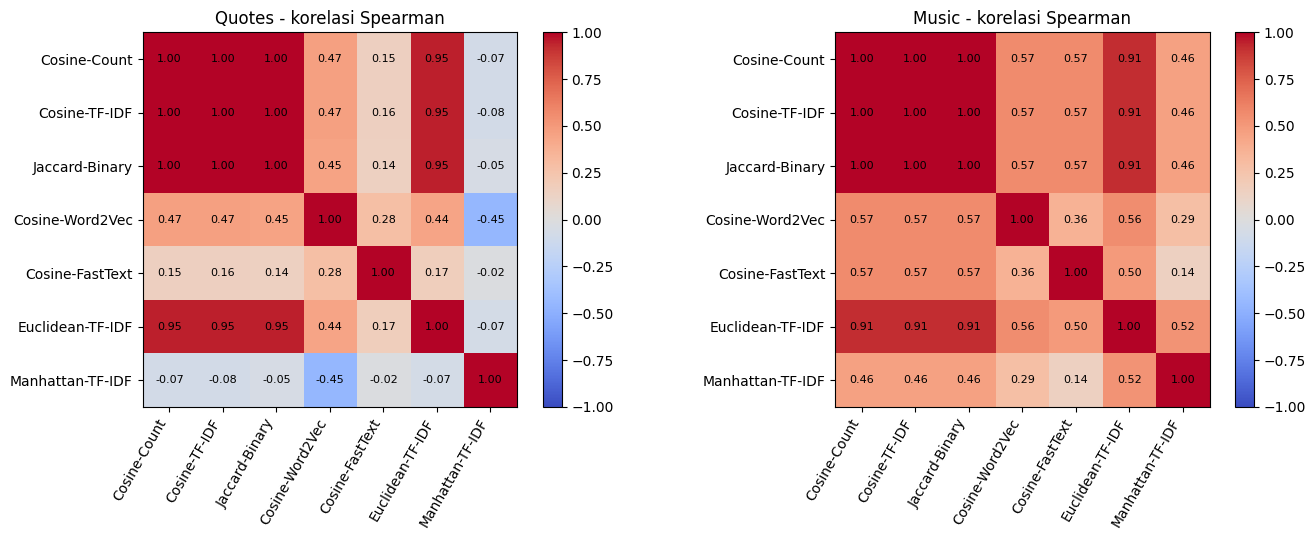

In [12]:
corr_methods = main_methods + ['Euclidean-TF-IDF', 'Manhattan-TF-IDF']
corrs = {}
for name in datasets:
    n = len(datasets[name]); iu = np.triu_indices(n, k=1)
    table = pd.DataFrame({m: sim[name][m][iu] for m in corr_methods})
    corrs[name] = table.corr(method='spearman')
    print(f"{name}: korelasi Spearman antar metode")
    display(corrs[name].round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, name in zip(axes, datasets):
    im = ax.imshow(corrs[name].values, cmap='coolwarm', vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr_methods))); ax.set_xticklabels(corr_methods, rotation=60, ha='right')
    ax.set_yticks(range(len(corr_methods))); ax.set_yticklabels(corr_methods)
    for i in range(len(corr_methods)):
        for j in range(len(corr_methods)):
            v = corrs[name].values[i, j]
            ax.text(j, i, '' if np.isnan(v) else f'{v:.2f}', ha='center', va='center', fontsize=8)
    ax.set_title(f'{name} - korelasi Spearman')
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()

In [13]:
rows = []
for name in datasets:
    n = len(datasets[name]); iu = np.triu_indices(n, k=1)
    for m in main_methods:
        v = sim[name][m][iu]
        rows.append({'Dataset': name, 'Metode': m, 'rata-rata': v.mean(), 'median': np.median(v), 'maks': v.max(), '% pasangan = 0': 100 * np.mean(v == 0)})
summary_sim = pd.DataFrame(rows).round(3)
display(summary_sim)

,Dataset,Metode,rata-rata,median,maks,% pasangan = 0
0,Quotes,Cosine-Count,0.022,0.000,0.470,83.265
1,Quotes,Cosine-TF-IDF,0.015,0.000,0.331,83.265
2,Quotes,Jaccard-Binary,0.010,0.000,0.250,83.265
3,Quotes,Cosine-Word2Vec,0.999,0.999,1.000,0.000
4,Quotes,Cosine-FastText,0.946,0.964,0.994,0.000
5,Music,Cosine-Count,0.046,0.000,0.816,87.619
6,Music,Cosine-TF-IDF,0.034,0.000,0.775,87.619
7,Music,Jaccard-Binary,0.029,0.000,0.667,87.619
8,Music,Cosine-Word2Vec,0.023,0.002,0.844,0.000
9,Music,Cosine-FastText,0.102,0.077,0.810,0.000


## **9. Pencarian Dokumen Berdasarkan Query (Top-K)**

In [18]:
queries = {'Quotes': "life is about love and dreams",
           'Music':  "love in the night sky"}
TOP_K = 5

def retrieve(name, query, top=TOP_K):
    d = datasets[name]; f = feat[name]
    q = finalize(pd.Series([preprocess(query)])).iloc[0]
    q_tokens = word_tokenize(q)
    scores = {}
    scores['TF-IDF + Cosine']     = cosine_similarity(f['vec_tfidf'].transform([q]), f['TF-IDF'])[0]
    scores['Count + Cosine']      = cosine_similarity(f['vec_count'].transform([q]), f['Count'])[0]
    qb = f['vec_bin'].transform([q]).toarray().astype(bool)
    jd = cdist(f['Binary BoW'].astype(bool), qb, metric='jaccard')[:, 0]
    scores['Binary + Jaccard']    = np.nan_to_num(1 - jd, nan=0.0)
    scores['Word2Vec + Cosine']   = cosine_similarity(doc_vector(q_tokens, f['w2v']).reshape(1, -1), f['Word2Vec'])[0]
    scores['FastText + Cosine']   = cosine_similarity(doc_vector(q_tokens, f['ft']).reshape(1, -1), f['FastText'])[0]
    return q, scores

retrieval = {}
for name, query in queries.items():
    q, scores = retrieve(name, query)
    retrieval[name] = scores
    print(f"{name} | query: '{query}' -> setelah preprocessing: '{q}'")
    for m, s in scores.items():
        idx = np.argsort(s)[::-1][:TOP_K]
        res = pd.DataFrame({'doc': idx, 'teks': datasets[name]['display'].iloc[idx].values, 'skor': s[idx].round(4)})
        print(f"{m}")
        display(res)

Quotes | query: 'life is about love and dreams' -> setelah preprocessing: 'life love dream'
TF-IDF + Cosine


,doc,teks,skor
0,49,"“Love does not begin and end the way we seem to think it does. Love is a battle, love ...",0.4596
1,40,"“A reader lives a thousand lives before he dies, said Jojen. The man who never reads l...",0.4408
2,19,“Life is what happens to us while we are making other plans.”,0.2736
3,20,"“I love you without knowing how, or when, or from where. I love you simply, without pr...",0.2404
4,22,"“If you judge people, you have no time to love them.”",0.2349


Count + Cosine


,doc,teks,skor
0,49,"“Love does not begin and end the way we seem to think it does. Love is a battle, love ...",0.5774
1,40,"“A reader lives a thousand lives before he dies, said Jojen. The man who never reads l...",0.5000
2,22,"“If you judge people, you have no time to love them.”",0.3536
3,19,“Life is what happens to us while we are making other plans.”,0.3536
4,20,"“I love you without knowing how, or when, or from where. I love you simply, without pr...",0.3487


Binary + Jaccard


...

,doc,teks,skor
0,11,sky Kromattic,0.25
1,6,Night pello,0.25
2,8,Night (Sleep) pello,0.20
3,0,Love Keyshia Cole,0.20
4,1,Love Musiq Soulchild,0.20


Word2Vec + Cosine


,doc,teks,skor
0,6,Night pello,0.4548
1,1,Love Musiq Soulchild,0.4130
2,0,Love Keyshia Cole,0.4100
3,8,Night (Sleep) pello,0.3495
4,2,LOVE. (feat. Zacari) Kendrick Lamar,0.3291


FastText + Cosine


,doc,teks,skor
0,11,sky Kromattic,0.6899
1,9,A Sky Full of Stars Coldplay,0.5771
2,10,Sky (Shining Bright) KC Lights,0.5516
3,6,Night pello,0.4280
4,1,Love Musiq Soulchild,0.3699


## **10. Irisan hasil antar metode**

In [19]:
for name in datasets:
    tops = {m: set(np.argsort(s)[::-1][:TOP_K]) for m, s in retrieval[name].items()}
    names = list(tops)
    overlap = pd.DataFrame([[len(tops[a] & tops[b]) for b in names] for a in names], index=names, columns=names)
    print(f"{name}: jumlah dokumen yang sama pada top-{TOP_K}")
    display(overlap)

Quotes: jumlah dokumen yang sama pada top-5


,TF-IDF + Cosine,Count + Cosine,Binary + Jaccard,Word2Vec + Cosine,FastText + Cosine
TF-IDF + Cosine,5,5,2,3,3
Count + Cosine,5,5,2,3,3
Binary + Jaccard,2,2,5,0,1
Word2Vec + Cosine,3,3,0,5,2
FastText + Cosine,3,3,1,2,5


Music: jumlah dokumen yang sama pada top-5


,TF-IDF + Cosine,Count + Cosine,Binary + Jaccard,Word2Vec + Cosine,FastText + Cosine
TF-IDF + Cosine,5,5,5,4,3
Count + Cosine,5,5,5,4,3
Binary + Jaccard,5,5,5,4,3
Word2Vec + Cosine,4,4,4,5,2
FastText + Cosine,3,3,3,2,5
